In [1]:
import matplotlib.pyplot as plt
import numpy as np
import networkx as nx
import mpmath


def generate_TF_graph():
    G = nx.Graph()
    G.add_edge(1, 2)
    G.add_edge(3, 4)
    G.add_edge(3, 1)
    G.add_edge(2, 4)

    return G

def map_TF_weights(k_diffusion, k_stability, N_diffusion, N_stability, sigma_1, sigma_2, dG_diffusion, w_13, w_31, w_24, w_42, k_unbinding, k_bT):
    # Diffusion
    w_12 = N_diffusion**2 * k_diffusion * mpmath.exp(1 / k_bT**2 * -(dG_diffusion + 3/2 * sigma_1**2)) 
    # w_21 = N_diffusion**2 * k_diffusion * mpmath.exp(1 / k_bT**2 * -(-dG_diffusion + 3/2 * sigma_1**2))
    w_21 = 0

    w_34 = N_diffusion**2 * k_diffusion * mpmath.exp(1 / k_bT**2 * -(dG_diffusion + 3/2 * sigma_2**2)) 
    # w_43 = N_diffusion**2 * k_diffusion * mpmath.exp(1 / k_bT**2 * -(-dG_diffusion + 3/2 * sigma_2**2))
    w_43 = 0
    # Stability 
    w_21 += k_stability * mpmath.exp(1 / k_bT * -(mpmath.sqrt(2 * mpmath.log(2 * N_stability)) * sigma_1))
    w_43 += k_stability * mpmath.exp(1 / k_bT * -(mpmath.sqrt(2 * mpmath.log(2 * N_stability)) * sigma_2))

    #Unbinding
    w_21 += k_unbinding
    w_43 += k_unbinding
    
    weights = {
        (1, 2): w_12,
        (2, 1): w_21,
        (3, 4): w_34,
        (4, 3): w_43,
        (1,3): w_13,
        (3,1): w_31,
        (2,4): w_24,
        (4,2): w_42,
        (1,1): 1,
        (2,2): 1,
        (3,3): 1,
        (4,4): 1
    }
    return weights

In [4]:
from dynamic_catalysis_model import *

spanning_trees = generate_spanning_trees(G)

for tree in spanning_trees:
    print(tree.edges())

[(1, 2), (1, 3), (2, 4)]
[(1, 3), (2, 4), (3, 4)]
[(1, 2), (2, 4), (3, 4)]
[(1, 2), (1, 3), (3, 4)]


In [66]:
from dynamic_catalysis_model import cycle_flux_fn

k_diffusion = 1
k_stability = 1
N_diffusion = 1
N_stability = 1
dG_diffusion = 0
k_bT = 1
k_unbinding = 0
cycles = [[2,2], [4,4]]
activation_coefficient = 1

sigma_ls = np.linspace(0, 5, 100)
activation_rate = []

G = generate_TF_graph()

for index, sigma in enumerate(sigma_ls):
    sigma_1 = sigma
    sigma_2 = sigma
    def f(**params):
        return 1

    w_13 = 1E11
    w_31 = 1E11
    w_24 = 1E11
    w_42 = 1E11
    flux = cycle_flux_fn(cycles, [], G, None, None, max_ss_rate_fn=f, weight_mapping_fn=map_TF_weights, \
                        k_diffusion=k_diffusion, k_stability=k_stability, N_diffusion=N_diffusion, \
                        N_stability=N_stability, sigma_1=sigma_1, sigma_2=sigma_2, dG_diffusion=dG_diffusion, w_13=w_13, w_31=w_31,\
                        w_24=w_24, w_42=w_42, k_unbinding=k_unbinding, k_bT=k_bT)
    activation_rate.append(flux[0])

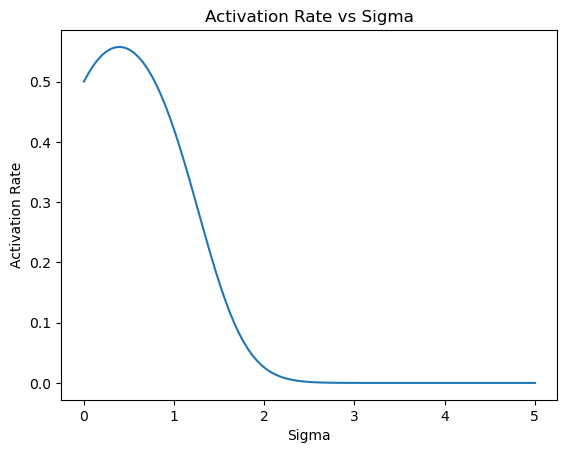

In [67]:
plt.figure()
plt.plot(sigma_ls, activation_rate)
# plt.yscale('log')
plt.xlabel('Sigma')
plt.ylabel('Activation Rate')
plt.title('Activation Rate vs Sigma')
plt.show()

In [88]:
import matplotlib.pyplot as plt
import matplotlib.colors
import numpy as np
from matplotlib.colors import LinearSegmentedColormap, LogNorm, Normalize
from dynamic_catalysis_model import max_rate_six_states, cycle_flux_fn, osc_midpoint_six_states, map_graph_weights_six_states

import mpmath
import numpy as np
import bokeh.layouts
import bokeh.models
import bokeh.plotting

from IPython.display import display
from jupyter_bokeh.widgets import BokehModel
from bokeh.io import output_notebook, export_svg, export_png
from bokeh.plotting import figure
from ipywidgets import interact

from bokeh.io import output_file, show, export_svgs
from bokeh.layouts import row
from bokeh.models import Ellipse, GraphRenderer, StaticLayoutProvider, Circle
from bokeh.palettes import Spectral6, Reds3, brewer
from bokeh.plotting import figure
from IPython.display import display
from bokeh.models import (Arrow, Label, NormalHead, OpenHead,
                          Plot, Range1d, TeeHead, VeeHead)
import matplotlib.cm as cm
from bokeh.models import MathML
import pickle as pkl
from matplotlib.colors import Normalize
import networkx as nx
output_notebook()


def heatmap(F1, F2, oscMidpoint, amplitude, **params):
    turnover_fold_increase = np.zeros(F1.shape)
    for i in range(F1.shape[0]):
        for j in range(F1.shape[1]):

            sigma_1 = 0
            sigma_2 = 10

            w_13 = F1[i, j]
            w_24 = F2[i, j]
            w_31 = F2[i, j] 
            w_42 = F2[i, j] 

            J_turnover, J_futile = cycle_flux_fn(w_13=w_13, w_24=w_24, w_31=w_31, w_42=w_42, sigma_1=sigma_1, sigma_2=sigma_2, **params)
        
            turnover_fold_increase[i, j] = J_turnover
    return turnover_fold_increase

class MidPointLogNorm(LogNorm):
    def __init__(self, vmin=None, vmax=None, midpoint=None, clip=False):
        LogNorm.__init__(self,vmin=vmin, vmax=vmax, clip=clip)
        self.midpoint=midpoint
    def __call__(self, value, clip=None):
        # I'm ignoring masked values and all kinds of edge cases to make a
        # simple example...
        x, y = [self.vmin, self.midpoint, self.vmax], [0, 0.5, 1]
        return np.ma.masked_array(np.interp(value, x, y))

Loading BokehJS ...

findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Fon

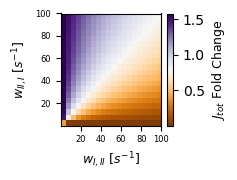

In [89]:
activation_rate = np.array(activation_rate)
max_activation = np.max(activation_rate)
idx = np.where(activation_rate == max_activation)[0][0]
osc_midpoint = sigma_ls[idx]
amplitude = osc_midpoint
max_frequency = 100
n_points = 20
frequencies_1 = np.linspace(1e-5, max_frequency, n_points)
frequencies_2 = np.linspace(1e-5, max_frequency, n_points)


palette = brewer['PuOr'][11][::-1]
palette = bokeh.palettes.interp_palette(palette, 400)

F1, F2 = np.meshgrid(frequencies_1, frequencies_2)
def f(**params):
    return max_activation
turnover_fold_increase = heatmap(F1, F2, turnover_cycles=cycles, futile_cycles=[], reaction_graph=G, oscMidpoint=osc_midpoint, k_diffusion=k_diffusion, N_diffusion=N_diffusion, \
                        N_stability=N_stability, dG_diffusion=dG_diffusion, k_stability=k_stability, k_bT=k_bT,max_ss_rate_fn=f, weight_mapping_fn=map_TF_weights, k_unbinding = 0, amplitude=amplitude)

cmap = LinearSegmentedColormap.from_list('mycmap', palette)
plt.figure(figsize=(2.4, 1.9))
plt.imshow(turnover_fold_increase, extent=(1e-5, max_frequency, 1e-5, max_frequency), origin='lower', aspect='auto', cmap=cmap)
plt.xlabel(r'$w_{I,II}\ [s^{-1}]$', fontsize=9, fontdict={'fontname': 'Lucida Sans'})
plt.ylabel(r'$w_{II,I}\ [s^{-1}]$', fontsize=9, fontdict={'fontname': 'Lucida Sans'})
plt.xticks([20, 40, 60, 80, 100], fontsize=6)
plt.yticks([20, 40, 60, 80, 100], fontsize=6)
ax = plt.gca()
for tick in ax.get_xticklabels():
    tick.set_fontname("Lucida Sans")
for tick in ax.get_yticklabels():
    tick.set_fontname("Lucida Sans")
cbar = plt.colorbar(label='$J_{tot}$ Fold Change')
cbar.set_label('$J_{tot}$ Fold Change', fontdict={'fontname': 'Lucida Sans'}, fontsize=9)
# cbar.set_ticks([1])
# cbar.set_ticklabels([ 1,], fontdict={'fontname': 'Lucida Sans'}, fontsize=6)
plt.tight_layout()

<>:23: SyntaxWarning: invalid escape sequence '\s'
<>:23: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_545643/3954403488.py:23: SyntaxWarning: invalid escape sequence '\s'
  ax.set_xlabel(f'$\sigma$', fontsize=9)


0.40404040404040403
0.40404040404040403
0.40404040404040403
0.40404040404040403
0.40404040404040403
0.40404040404040403
0.40404040404040403


findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Fon

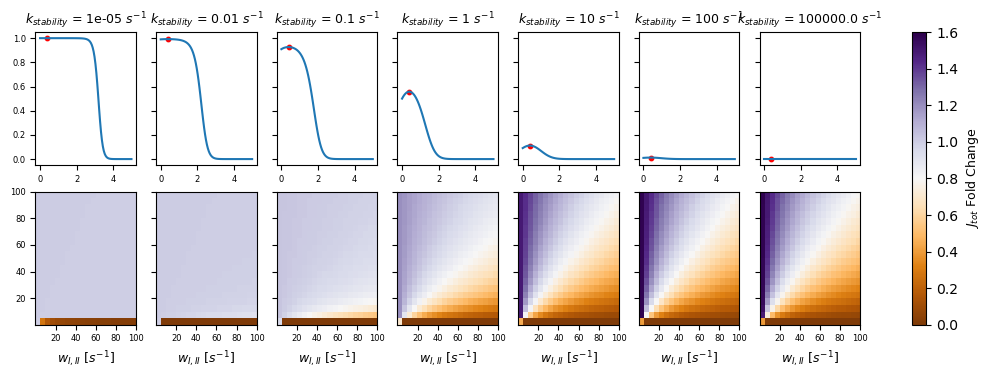

In [90]:
k_stability_ls = [1e-5, 0.01, 0.1, 1, 10, 100, 1e5]
fig, axs = plt.subplots(2, 7, figsize=(1.9 * 7, 1.9 * 2), sharey='row')
ax = axs[0][0]
for k_index, k_stability in enumerate(k_stability_ls):
    activation_rate = []
    for index, sigma in enumerate(sigma_ls):
        sigma_1 = sigma
        sigma_2 = sigma
        def f(**params):
            return 1

        w_13 = 1E11
        w_31 = 1E11
        w_24 = 1E11
        w_42 = 1E11
        flux = cycle_flux_fn(cycles, [], G, None, None, max_ss_rate_fn=f, weight_mapping_fn=map_TF_weights, \
                            k_diffusion=k_diffusion, k_stability=k_stability, N_diffusion=N_diffusion, \
                            N_stability=N_stability, sigma_1=sigma_1, sigma_2=sigma_2, dG_diffusion=dG_diffusion, w_13=w_13, w_31=w_31,\
                            w_24=w_24, w_42=w_42, k_unbinding=0, k_bT=k_bT)
        activation_rate.append(flux[0])
    ax = axs[0][k_index]
    ax.plot(sigma_ls, activation_rate)
    ax.set_xlabel(f'$\sigma$', fontsize=9)
    ax.set_title(f'$k_{{stability}}$ = {k_stability} $s^{{-1}}$', fontsize=9, fontdict={'fontname': 'Lucida Sans'})
    ax.tick_params(axis='both', which='major', labelsize=6)
    activation_rate = np.array(activation_rate)
    max_activation = np.max(activation_rate)
    idx = np.where(activation_rate == max_activation)[0][0]
    osc_midpoint = sigma_ls[idx]
    ax.scatter(osc_midpoint, max_activation, color='red', s=10)
    for tick in ax.get_xticklabels():
        tick.set_fontname("Lucida Sans")
    for tick in ax.get_yticklabels():
        tick.set_fontname("Lucida Sans")
    print(osc_midpoint)
    def f(**params):
        return max_activation
    turnover_fold_increase = heatmap(F1, F2, turnover_cycles=cycles, futile_cycles=[], reaction_graph=G, oscMidpoint=osc_midpoint, k_diffusion=k_diffusion, N_diffusion=N_diffusion, amplitude=0.5,\
                        N_stability=N_stability, dG_diffusion=dG_diffusion, k_stability=k_stability, k_bT=k_bT,max_ss_rate_fn=f, weight_mapping_fn=map_TF_weights, k_unbinding = 0 )
    # print(np.max(turnover_fold_increase))
    cmap = LinearSegmentedColormap.from_list('mycmap', palette)
    
    ax = axs[1][k_index]
    normalizer = Normalize(0, 1.6)
    im = cm.ScalarMappable(norm=normalizer, cmap=cmap)
    ax.imshow(turnover_fold_increase, extent=(1e-5, max_frequency, 1e-5, max_frequency), origin='lower', aspect='auto', norm=normalizer, cmap=cmap)
    ax.set_xlabel(r'$w_{I,II}\ [s^{-1}]$', fontsize=9, fontdict={'fontname': 'Lucida Sans'})
    # ax.set_ylabel(r'$w_{II,I}\ [s^{-1}]$', fontsize=9, fontdict={'fontname': 'Lucida Sans'})
    ax.set_xticks([20, 40, 60, 80, 100])
    ax.set_yticks([20, 40, 60, 80, 100])
    ax.tick_params(axis='both', which='major', labelsize=6)
    for tick in ax.get_xticklabels():
        tick.set_fontname("Lucida Sans")
    for tick in ax.get_yticklabels():
        tick.set_fontname("Lucida Sans")

cbar = fig.colorbar(im, ax=axs.ravel().tolist(), cmap=cmap)
cbar.set_label('$J_{tot}$ Fold Change', fontdict={'fontname': 'Lucida Sans'}, fontsize=9)
# cbar.set_ticks([0.4, 0.5, 1, 1.5])
# cbar.set_ticklabels([0.4, 0.5, 1, 1.5], fontdict={'fontname': 'Lucida Sans'}, fontsize=6)
# plt.tight_layout()
plt.show()
    

In [91]:
from dynamic_catalysis_model import cycle_flux_fn

k_diffusion = 1
k_stability = 1
N_diffusion = 1
N_stability = 1
dG_diffusion = 0
k_bT = 1
k_unbinding = 0
cycles = [[2,2], [4,4]]
activation_coefficient = 1

sigma_ls = np.linspace(0, 5, 100)
activation_rate = []

G = generate_TF_graph()

for index, sigma in enumerate(sigma_ls):
    sigma_1 = sigma
    sigma_2 = sigma
    def f(**params):
        return 1

    w_13 = 1E-11
    w_31 = 1E-11
    w_24 = 1E-11
    w_42 = 1E-11
    flux = cycle_flux_fn(cycles, [], G, None, None, max_ss_rate_fn=f, weight_mapping_fn=map_TF_weights, \
                        k_diffusion=k_diffusion, k_stability=k_stability, N_diffusion=N_diffusion, \
                        N_stability=N_stability, sigma_1=sigma_1, sigma_2=sigma_2, dG_diffusion=dG_diffusion, w_13=w_13, w_31=w_31,\
                        w_24=w_24, w_42=w_42, k_unbinding=k_unbinding, k_bT=k_bT)
    activation_rate.append(flux[0])

Text(0.5, 1.0, 'Activation Rate vs $w_{I,II}$')

findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.


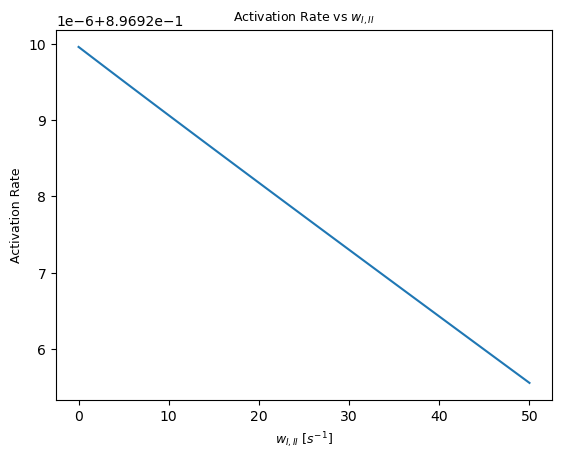

In [92]:
v   = np.linspace(1E-5, 50, 100)
w_31 = 40
def f(**params):
    return np.max(activation_rate)
activation_rate_dss = []
for w_13 in w_13_ls:
    w_24 = w_13
    w_31 = w_31
    w_42 = w_31
    flux = cycle_flux_fn(cycles, [], G, None, None, max_ss_rate_fn=f, weight_mapping_fn=map_TF_weights, k_diffusion=k_diffusion, k_stability=k_stability, N_diffusion=N_diffusion, N_stability=N_stability, sigma_1=0, sigma_2=
                        10, dG_diffusion=dG_diffusion, k_unbinding=0, k_bT=k_bT, w_13=w_13, w_31=w_31, w_24=w_24, w_42=w_42)
    activation_rate_dss.append(flux[0])
plt.figure()
plt.plot(w_13_ls, activation_rate_dss)
# plt.xscale('log')
plt.xlabel(r'$w_{I,II}\ [s^{-1}]$', fontsize=9, fontdict={'fontname': 'Lucida Sans'})
plt.ylabel('Activation Rate', fontsize=9, fontdict={'fontname': 'Lucida Sans'})
plt.title('Activation Rate vs $w_{I,II}$', fontsize=9, fontdict={'fontname': 'Lucida Sans'})

Text(0.5, 1.0, 'Activation Rate vs $w_{I,II}$')

findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.


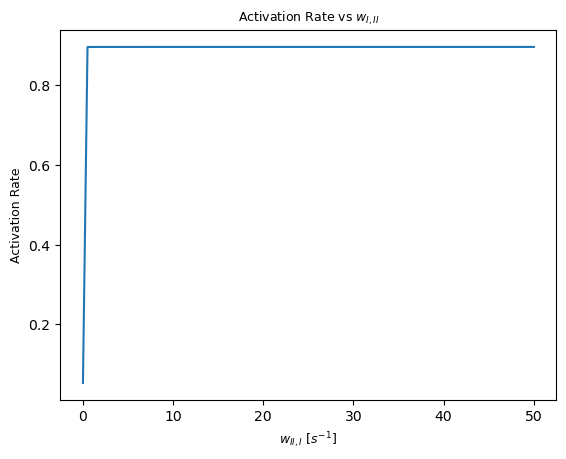

In [93]:
w_31_ls = np.linspace(1e-5, 50, 100)
w_13 = 40
def f(**params):
    return np.max(activation_rate)
activation_rate_dss = []
for w_31 in w_31_ls:
    w_24 = w_13
    w_31 = w_31
    w_42 = w_31
    flux = cycle_flux_fn(cycles, [], G, None, None, max_ss_rate_fn=f, weight_mapping_fn=map_TF_weights, k_diffusion=k_diffusion, k_stability=k_stability, N_diffusion=N_diffusion, N_stability=N_stability, sigma_1=0, sigma_2=
                        10, dG_diffusion=dG_diffusion, k_unbinding=0, k_bT=k_bT, w_13=w_13, w_31=w_31, w_24=w_24, w_42=w_42)
    activation_rate_dss.append(flux[0])
plt.figure()
plt.plot(w_31_ls, activation_rate_dss)
plt.xlabel(r'$w_{II,I}\ [s^{-1}]$', fontsize=9, fontdict={'fontname': 'Lucida Sans'})
plt.ylabel('Activation Rate', fontsize=9, fontdict={'fontname': 'Lucida Sans'})
plt.title('Activation Rate vs $w_{I,II}$', fontsize=9, fontdict={'fontname': 'Lucida Sans'})

In [94]:
#In all the examples, this will be fixed:

#Define the grid:
stp_ar=np.arange(1e-11,20,0.1) #The mathematica files to check the results assume a grid spacing of 0.005. Change that if this is modified. 
pos_ar=np.arange(1e-11,10,0.05)

minp=1e-3
maxp=1e3


defaultsettings={'pars_limit':[minp,maxp],
           'row_ar':stp_ar,
          'col_ar':pos_ar,
          'seed':1,
         'mat':None,
         'mat_pars':None}


defaultargs={'niters':5, #for testing purposes only 5 iterations, or it will take very long
      'niters_conv':100,
      'niters_conv_points':1000,
      'niters_save':2,
      'prob_par':0.5,
      'prob_replace':0.5,
      'extr_uniform':[-1,1],
      'L_project':10,
      'plotting':True,
      'verbose':True,
       'dofirstmutate':True,
      'dopullcentroids':True,
      'dopulltangents':True} 

In [97]:
import os
from utilsGRF import BoundaryFinder as BF

futile_cycles = [[1,3], [2,4]]

#code that runs the boundary exploration in the space given by the function myfN2
#set plotting:False in args dict when running for many iterations, so that no plots are shown
def rate_fn(*params):
    alpha_24, alpha_42, alpha_13, alpha_31, amplitude_1, amplitude_2 = params[0]
    def f(**params):
        return np.max(activation_rate)
    amplitude_1, amplitude_2 = np.log10(amplitude_1), np.log10(amplitude_2)
    return cycle_flux_fn(cycles, futile_cycles, G, None, None, max_ss_rate_fn=f,\
                        weight_mapping_fn=map_TF_weights, k_diffusion=k_diffusion,\
                        k_stability=k_stability, N_diffusion=N_diffusion, \
                        N_stability=N_stability, sigma_1=amplitude_1, sigma_2=amplitude_2,\
                        dG_diffusion=dG_diffusion, k_unbinding=0, k_bT=k_bT, w_13=w_13,\
                        w_31=w_31, w_24=w_24, w_42=w_42)


outfolder="test"
if not os.path.isdir(outfolder):
    os.mkdir(outfolder)
name_save="namesave_g20000_sweep"
outfolder_final=outfolder
name='%s_last'%(name_save)


settings=defaultsettings.copy()
# constraints={1:{'target':0,'lt':1},3:{'target':2,'lt':1},5:{'target':4,'lt':1}} #the coefficients in the numerator are at most as large as the corresponding in the denominator

# settings['constraints']=constraints
settings['compute_x_y_f']=rate_fn
settings['npars']=6

#Initialise and get first 10 points

BE=BF.BoundaryExplorer(**settings)
BE.get_initial_points(10)

#Extend boundary

args=defaultargs.copy()
args["niters"]=20 #just for testing purposes
args['folder_save']=outfolder
args['name_save']=name_save
BE.extend_boundary(**args)


np.save(os.path.join(outfolder_final,'mat_'+name+'.npy'),BE.mat)
np.save(os.path.join(outfolder_final,'mat_pars_'+name+'.npy'),BE.mat_pars)

KeyboardInterrupt: 